# A. Veri Tanıtımı

### 1. Veri Setinin Adı ve Bağlantısı

**Veri setinin adı:** Used Car Price Prediction Dataset

**Veri setinin sahibi:** Taeef Najib

**Veri kaynağı:** Kaggle

**Veri setinin bağlantısı:**  
https://www.kaggle.com/datasets/taeefnajib/used-car-price-prediction-dataset

### 2. Veri Kaynağı, Lisans ve Erişim Tarihi

Veri seti Kaggle platformundan alınmıştır. Veri setinin orijinal kaynağı Cars.com araç ilanlarıdır.

**Lisans:** Creative Commons Attribution 4.0 International (CC BY 4.0)

**Lisans bağlantısı:** https://creativecommons.org/licenses/by/4.0/

**Erişim tarihi:** 07.11.2026

Veri seti kullanılırken veri sahibine atıfta bulunulmuştur.

### 3. Veri Formatı

Veri seti CSV (Comma-Separated Values) formatındadır. Python programlama dili ve Pandas kütüphanesi kullanılarak okunmuştur.

### 4. Satır ve Sütunların Anlamı

Her satır ikinci el bir aracı temsil etmektedir. Veri setinde toplam 4.009 satır ve 12 sütun bulunmaktadır.

Sütunların açıklamaları:

| Sütun | Açıklama |
|---|---|
| brand | Araç markası |
| model | Araç modeli |
| model_year | Araç üretim yılı |
| milage | Araç kilometresi (mil) |
| fuel_type | Yakıt türü |
| engine | Motor bilgisi |
| transmission | Şanzıman türü |
| ext_col | Dış renk |
| int_col | İç renk |
| accident | Kaza geçmişi |
| clean_title | Temiz başlık bilgisi |
| price | Araç fiyatı (ABD doları) |

### 5. Ölçü Birimi ve Gözlem Sayısı

- Gözlem sayısı: 4.009 araç
- Değişken sayısı: 12 sütun
- Fiyat birimi: ABD doları ($)
- Mesafe birimi: Mil (mi)
- Yıl birimi: Takvim yılı

### 6. Veri Türü

Veri seti gerçek ikinci el araç ilanlarından elde edilmiş verilerden oluşmaktadır. Temsili veya yapay olarak oluşturulmuş bir veri seti değildir.

### 7. Projenin Amacı

Bu projenin amacı, ikinci el araçların marka, model, üretim yılı, kilometre ve diğer özelliklerini kullanarak araç fiyatlarını tahmin etmektir.

Bu amaç doğrultusunda Linear Regression ve Random Forest algoritmalarından yararlanılmaktadır.

### 8. Ekip Üyelerinin Görevleri

Ekip üyelerinin görev dağılımı:

- Veri setinin araştırılması ve temin edilmesi: [İsim]
- Veri analizi ve düzenlenmesi: [İsim]
- Grafiklerin oluşturulması: [İsim]
- Makine öğrenmesi modellerinin geliştirilmesi: [İsim]
- Proje raporu ve dokümantasyon: [İsim]

In [15]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

veri_yolu = "/content/used_cars.csv"

veri = pd.read_csv(veri_yolu)

print(veri.head())

      brand                            model  model_year      milage  \
0      Ford  Utility Police Interceptor Base        2013  51,000 mi.   
1   Hyundai                     Palisade SEL        2021  34,742 mi.   
2     Lexus                    RX 350 RX 350        2022  22,372 mi.   
3  INFINITI                 Q50 Hybrid Sport        2015  88,900 mi.   
4      Audi        Q3 45 S line Premium Plus        2021   9,835 mi.   

       fuel_type                                             engine  \
0  E85 Flex Fuel  300.0HP 3.7L V6 Cylinder Engine Flex Fuel Capa...   
1       Gasoline                               3.8L V6 24V GDI DOHC   
2       Gasoline                                     3.5 Liter DOHC   
3         Hybrid  354.0HP 3.5L V6 Cylinder Engine Gas/Electric H...   
4       Gasoline                         2.0L I4 16V GDI DOHC Turbo   

        transmission                 ext_col int_col  \
0        6-Speed A/T                   Black   Black   
1  8-Speed Automatic        

In [16]:
print("Veri setinin boyutu:", veri.shape)

print("\nSütunlar:")
print(veri.columns.tolist())

print("\nEksik veriler:")
print(veri.isna().sum())

print("\nVeri setinin bilgileri:")
veri.info()

print("\nİstatistiksel bilgiler:")
print(veri.describe())

Veri setinin boyutu: (4009, 12)

Sütunlar:
['brand', 'model', 'model_year', 'milage', 'fuel_type', 'engine', 'transmission', 'ext_col', 'int_col', 'accident', 'clean_title', 'price']

Eksik veriler:
brand             0
model             0
model_year        0
milage            0
fuel_type       170
engine            0
transmission      0
ext_col           0
int_col           0
accident        113
clean_title     596
price             0
dtype: int64

Veri setinin bilgileri:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4009 entries, 0 to 4008
Data columns (total 12 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   brand         4009 non-null   object
 1   model         4009 non-null   object
 2   model_year    4009 non-null   int64 
 3   milage        4009 non-null   object
 4   fuel_type     3839 non-null   object
 5   engine        4009 non-null   object
 6   transmission  4009 non-null   object
 7   ext_col       4009 non-null   obj

In [17]:
veri["price"] = pd.to_numeric(
    veri["price"].str.replace(r"[$,]", "", regex=True)
)

veri["milage"] = pd.to_numeric(
    veri["milage"].str.replace(r"[, mi.]", "", regex=True)
)

print("Ortalama araç fiyatı:", veri["price"].mean())
print("En yüksek araç fiyatı:", veri["price"].max())
print("En düşük araç fiyatı:", veri["price"].min())
print("Ortalama kilometre:", veri["milage"].mean())

Ortalama araç fiyatı: 44553.190321776005
En yüksek araç fiyatı: 2954083
En düşük araç fiyatı: 2000
Ortalama kilometre: 64717.55101022699


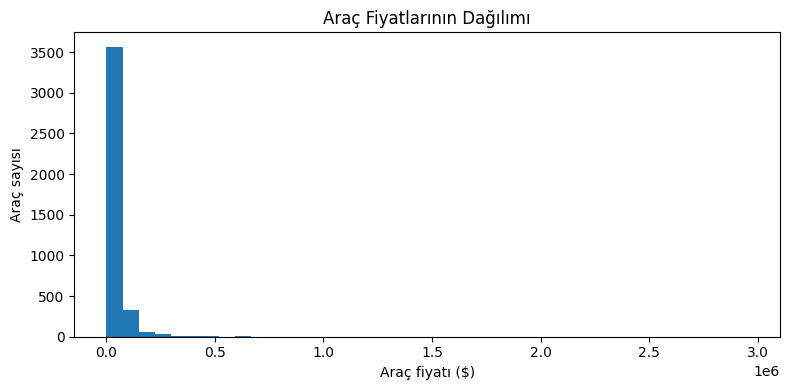

In [18]:
klasor = Path("sonuc")
klasor.mkdir(exist_ok=True)

fig, ax = plt.subplots(figsize=(8, 4))

ax.hist(veri["price"], bins=40)

ax.set_xlabel("Araç fiyatı ($)")
ax.set_ylabel("Araç sayısı")
ax.set_title("Araç Fiyatlarının Dağılımı")

fig.tight_layout()
fig.savefig(klasor / "fiyat_dagilimi.png", dpi=160)
plt.show()

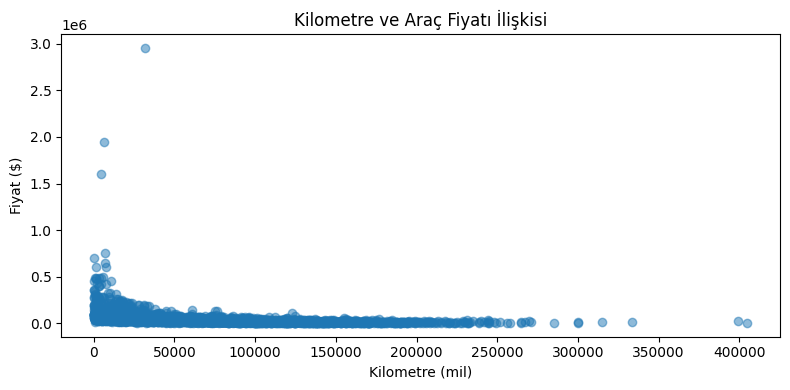

In [19]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(veri["milage"], veri["price"], alpha=0.5)

ax.set_xlabel("Kilometre (mil)")
ax.set_ylabel("Fiyat ($)")
ax.set_title("Kilometre ve Araç Fiyatı İlişkisi")

fig.tight_layout()
fig.savefig(klasor / "kilometre_fiyat.png", dpi=160)
plt.show()

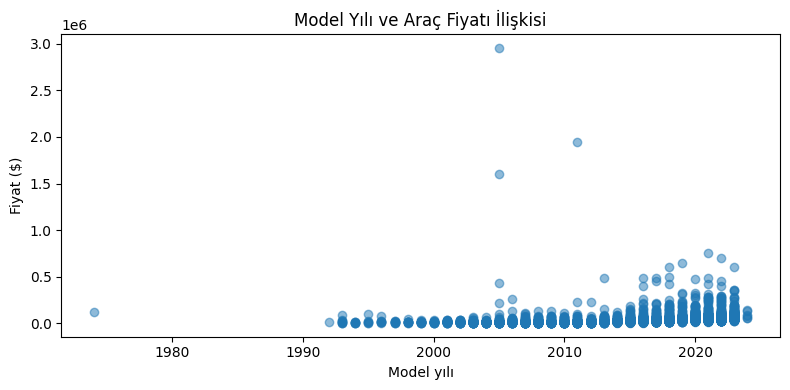

In [20]:
fig, ax = plt.subplots(figsize=(8, 4))

ax.scatter(veri["model_year"], veri["price"], alpha=0.5)

ax.set_xlabel("Model yılı")
ax.set_ylabel("Fiyat ($)")
ax.set_title("Model Yılı ve Araç Fiyatı İlişkisi")

fig.tight_layout()
fig.savefig(klasor / "yil_fiyat.png", dpi=160)
plt.show()

In [21]:
veri.to_csv(
    klasor / "kullanilan_veri.csv",
    index=False
)

print("Dosyalar başarıyla kaydedildi.")

Dosyalar başarıyla kaydedildi.


# E. Akademik Yorum

**Veri kaynağı ve değişkenler:**

İncelenen veri seti 4.009 adet ikinci el araç kaydından oluşmaktadır. Araç markası, modeli, üretim yılı, kilometresi ve fiyatı gibi değişkenler bulunmaktadır.

**Toplam / ortalama ve birimler:**

Araçların ortalama fiyatı 44.553,19 dolar, ortalama kilometresi ise 64.717,55 mildir. En düşük araç fiyatı 2.000 dolar, en yüksek araç fiyatı 2.954.083 dolardır.

**Grafikte görülen bulgular:**

Fiyat dağılımı grafiğinde araç fiyatlarının farklı aralıklarda yoğunlaştığı görülmektedir. Kilometre ve fiyat grafiğinde genel olarak negatif yönlü bir ilişki gözlemlenmektedir. Model yılı ve fiyat grafiğinde ise yeni model araçların genel olarak daha yüksek fiyatlara sahip olabildiği görülmektedir.

**Sınırlılıklar:**

Veri setinde yakıt türü, kaza bilgisi ve temiz başlık bilgisi sütunlarında eksik değerler bulunmaktadır. Ayrıca araçların marka, model ve donanım farklılıkları fiyatları etkileyebilmektedir. Veri setindeki uç fiyat değerleri analiz sonuçlarını etkileyebilir.

**Ekipçe yapılan işlem:**

CSV dosyası Python ve Pandas kütüphanesi kullanılarak incelenmiş, eksik veriler kontrol edilmiş, sayısal değişkenler analiz edilmiş ve Matplotlib ile grafikler oluşturulmuştur.

# F. Teslim Kontrolü

- [x] Çalışır `.ipynb` dosyası
- [x] CSV veri seti
- [x] Veri kaynağı ve lisans bilgilerinin doğrulanması
- [x] En az 1 açıklamalı grafik (3 grafik oluşturuldu)
- [x] Toplam ve ortalama hesaplamaları
- [x] 4–5 cümlelik akademik yorum
- [ ] README dosyasında ekip katkılarının belirtilmesi
- [ ] GitHub repo bağlantısının eklenmesi
- [ ] Ekip üyelerinin isimlerinin ve görevlerinin tamamlanması
- [x] Gizli/kişisel veri ve API anahtarı bulunmaması
